# 05 · Model Comparison — the bake-off, *from scratch*

**Phase goal:** fairly compare several regressors with **cross-validation** and
see *why* tree ensembles win on tabular data.

Unlike the original notebook (which reads a saved results file), this one
**actually trains every model itself**, so you can watch the numbers appear.

| Family | How it learns | What to expect |
| :-- | :-- | :-- |
| **Ridge (linear)** | one weighted sum of the inputs | underfits — price is non-linear |
| **Decision Tree** | one greedy flowchart of yes/no splits | overfits, high variance |
| **Random Forest** | *bagging* — average of many trees | strong, little tuning |
| **HistGradientBoosting** | *boosting* — each tree fixes the last one's errors | strong, fast |
| **XGBoost / LightGBM** | regularised boosting | usually best on tabular data |

In [1]:
# --- Self-contained setup: schema, cleaning, features, bands ---------------
# (In the real project these live in src/car_pricing/*. Here we write them out
#  so this notebook imports nothing from the project.)
import warnings
warnings.filterwarnings("ignore")   # hide library deprecation notices for clean output

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder

DATA_PATH     = "../data/raw/cars24-car-price-cleaned-new.csv.gz"
TARGET        = "selling_price"
TARGET_ENCODE = ["make", "model"]
NUMERIC       = ["km_driven", "mileage", "engine", "max_power", "age"]
FLAGS         = ["Individual", "Trustmark Dealer", "Diesel", "Electric", "LPG",
                 "Petrol", "Manual", "Seats_5", "Seats_Above_5"]
FEATURES      = TARGET_ENCODE + NUMERIC + FLAGS
BAND_LABELS   = ["Low", "Medium", "High"]
TEST_SIZE, RANDOM_STATE, CV_FOLDS = 0.2, 42, 3


def clean(df):
    df = df.rename(columns={"5": "Seats_5", ">5": "Seats_Above_5"})
    df = df.dropna(subset=[TARGET])
    df = df[df[TARGET] > 0].dropna()
    for c in TARGET_ENCODE:
        df[c] = df[c].astype(str).str.strip().str.upper()
    return df.reset_index(drop=True)


def build_preprocessor():
    """Target-encode make/model; pass numeric + flag columns through."""
    return ColumnTransformer([
        ("target_enc", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), TARGET_ENCODE),
        ("passthrough", "passthrough", NUMERIC + FLAGS),
    ], remainder="drop")


def band_edges(prices):
    edges = [float(np.quantile(prices, q)) for q in (0.0, 1/3, 2/3, 1.0)]
    for i in range(1, len(edges)):
        if edges[i] <= edges[i - 1]:
            edges[i] = edges[i - 1] + 0.01
    return [round(e, 2) for e in edges]


def price_to_band(prices, edges):
    prices = np.asarray(prices, dtype=float)
    idx = np.clip(np.digitize(prices, edges[1:-1]), 0, len(BAND_LABELS) - 1)
    return np.array(BAND_LABELS)[idx]


df = clean(pd.read_csv(DATA_PATH))
X = df[FEATURES].copy()
y = df[TARGET].copy()
print(f"{len(df):,} rows | {len(FEATURES)} features")

19,820 rows | 16 features


In [2]:
def model_zoo():
    """Name -> a fresh, unfitted regressor. Modest, comparable settings so the
    bake-off is a FAIR fight, not a tuning contest (we tune later, in nb 08)."""
    from sklearn.linear_model import Ridge
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

    zoo = {
        "Ridge (linear)": Ridge(alpha=1.0, random_state=RANDOM_STATE),
        "Decision Tree":  DecisionTreeRegressor(max_depth=12, min_samples_leaf=8, random_state=RANDOM_STATE),
        "Random Forest":  RandomForestRegressor(n_estimators=200, max_depth=18,
                                                min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06,
                                                              max_depth=8, random_state=RANDOM_STATE),
    }
    # Add the gradient-boosting libraries only if they are installed.
    try:
        from xgboost import XGBRegressor
        zoo["XGBoost"] = XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.05,
                                      subsample=0.9, colsample_bytree=0.9, n_jobs=-1,
                                      random_state=RANDOM_STATE, verbosity=0)
    except ImportError:
        pass
    try:
        from lightgbm import LGBMRegressor
        zoo["LightGBM"] = LGBMRegressor(n_estimators=600, num_leaves=63, learning_rate=0.05,
                                        subsample=0.9, colsample_bytree=0.9, n_jobs=-1,
                                        random_state=RANDOM_STATE, verbosity=-1)
    except ImportError:
        pass
    return zoo


print("candidates:", list(model_zoo()))

candidates: ['Ridge (linear)', 'Decision Tree', 'Random Forest', 'HistGradientBoosting', 'XGBoost', 'LightGBM']


### Cross-validation, done by hand (and why we fit the encoder *inside* the fold)
**K-fold CV** splits the training data into K parts; each part takes a turn as
the validation set while the other K-1 train the model. We average the error.

The subtle, important bit: the **target encoder must be fit only on each fold's
training rows**, then applied to its validation rows. If we encoded once up front
using the whole dataset, the validation prices would leak into the encoding and
our scores would be dishonestly good. We do it the correct way below.

In [3]:
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
import time

# Hold out a test set now so CV only ever sees the TRAINING data.
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
results = {}

print(f"{CV_FOLDS}-fold CV — MAE in Lakhs (lower is better)\n")
print(f"  {'Model':<24}{'CV MAE':>9}{'+/-std':>9}{'time(s)':>9}")
print("  " + "-" * 49)
for name, base in model_zoo().items():
    fold_maes, t0 = [], time.perf_counter()
    for tr_idx, val_idx in cv.split(X_tr):
        Xt, Xv = X_tr.iloc[tr_idx], X_tr.iloc[val_idx]
        yt, yv = y_tr.iloc[tr_idx], y_tr.iloc[val_idx]

        pre = build_preprocessor()          # a fresh encoder per fold ...
        Xt_e = pre.fit_transform(Xt, yt)    # ... fit on THIS fold's train rows only
        Xv_e = pre.transform(Xv)            # ... then applied to its val rows

        est = clone(base)                   # a fresh, unfitted model per fold
        est.fit(Xt_e, yt)
        fold_maes.append(mean_absolute_error(yv, est.predict(Xv_e)))

    arr = np.array(fold_maes)
    results[name] = {"cv_mae": arr.mean(), "cv_std": arr.std(),
                     "cv_time_s": time.perf_counter() - t0}
    print(f"  {name:<24}{arr.mean():>9.3f}{arr.std():>9.3f}{results[name]['cv_time_s']:>9.1f}")

3-fold CV — MAE in Lakhs (lower is better)

  Model                      CV MAE   +/-std  time(s)
  -------------------------------------------------
  Ridge (linear)              1.184    0.027      0.2


  Decision Tree               0.860    0.005      0.2


  Random Forest               0.745    0.004      2.2


  HistGradientBoosting        0.731    0.009      6.8


  XGBoost                     0.708    0.009      3.0


  LightGBM                    0.715    0.004      6.4


In [4]:
# Rank the candidates by cross-validated MAE and show the table.
tbl = pd.DataFrame(results).T.sort_values("cv_mae")
tbl.round(3)

,cv_mae,cv_std,cv_time_s
XGBoost,0.708,0.009,3.021
LightGBM,0.715,0.004,6.412
HistGradientBoosting,0.731,0.009,6.849
Random Forest,0.745,0.004,2.211
Decision Tree,0.860,0.005,0.187
Ridge (linear),1.184,0.027,0.166


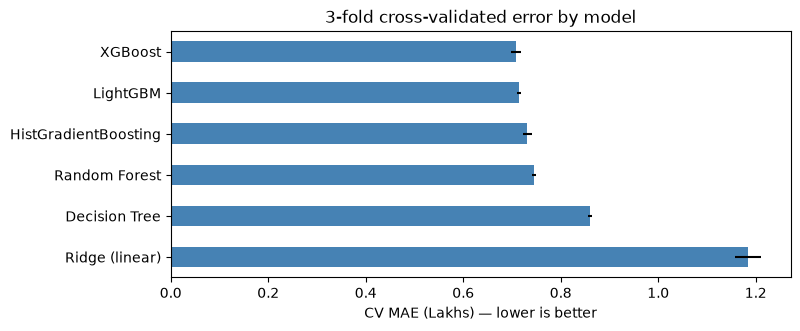

In [5]:
import matplotlib.pyplot as plt

ax = tbl["cv_mae"].plot.barh(xerr=tbl["cv_std"], figsize=(8, 3.2), color="steelblue")
ax.set_xlabel("CV MAE (Lakhs) — lower is better")
ax.set_title(f"{CV_FOLDS}-fold cross-validated error by model")
ax.invert_yaxis()
plt.show()

### What the numbers show
- **Linear** trails badly: price depends on non-linear interactions
  (brand × age × engine) that a single weighted sum can't capture.
- A **single decision tree** improves a lot but is the weakest ensemble baseline.
- **Random Forest** (bagging) and the **boosters** cluster at the top; the
  gradient boosters usually edge out the forest with fewer, shallower trees — and
  much smaller models.
- **XGBoost vs LightGBM** is typically a near-tie (well within one standard
  deviation). *Which one ships* is decided in nb 06 — and, as we'll see, it isn't
  purely about MAE.